# Real-ESRGAN • L4 GPU • Google Drive • `uv` only
**Form-first Colab notebook** adapted to [`orioninsist/Real-ESRGAN`](https://github.com/orioninsist/Real-ESRGAN). Designed for logos, icons and photos, with optional square PNG output for QR composition.

**How to run:** In Colab choose **Runtime → Change runtime type → GPU**, then select **L4** if offered. High-RAM is optional; it does *not* increase the L4 GPU's VRAM. Run cells in order. All code cells start in **Form view** with settings exposed and source hidden; use **Show code** to inspect them.

**Daily behavior:** The notebook mounts Drive each *new Colab session*, keeps repository/model weights and uv's download cache in Drive, and checks whether files already exist before downloading. Legacy BasicSR packages may still fail on newer Python/PyTorch versions. Colab's temporary `/content` environment and installed Python packages are lost after runtime resets; they must be restored in each fresh session. Installation of packages is performed **only using `uv`**, not `pip`. Colab must have internet access for the first run.

**Safety:** Don't execute untrusted notebook code; Drive mounting grants the runtime access to your selected Drive. Large input images or 4× output can exceed *system RAM* even when L4 VRAM is sufficient. No notebook can guarantee uninterrupted L4 allocation, unlimited compute units, or identical future Colab runtimes.

## 1 · Connect Drive and choose persistence
This authenticates Drive, creates a private working folder, and shows your GPU and Python version. **Run after selecting a GPU runtime.**

In [1]:
# @title 1. Google Drive, GPU & Python checks { display-mode: "form" }
drive_folder = "Real-ESRGAN-Colab" # @param {type:"string"}
require_l4 = True # @param {type:"boolean"}
require_gpu = True # @param {type:"boolean"}
cache_uv_downloads = True # @param {type:"boolean"}
import os, sys, pathlib, subprocess, re, json
from google.colab import drive
drive.mount("/content/drive")
if "/" in drive_folder or "\\" in drive_folder or drive_folder in ("", ".", ".."):
    raise ValueError("drive_folder must be a simple folder name, without slashes.")
ROOT=pathlib.Path("/content/drive/MyDrive") / drive_folder
for sub in ("repository", "weights", "uploads", "outputs", "uv-cache"):
    (ROOT/sub).mkdir(parents=True,exist_ok=True)
os.environ["UV_CACHE_DIR"]=str(ROOT/"uv-cache") if cache_uv_downloads else "/content/uv-cache"
print("Python:", sys.version.split()[0], "| executable:",sys.executable)
if sys.version_info < (3,10) or sys.version_info >= (3,14):
    raise RuntimeError("Unsupported/unverified Python. Use a Colab runtime with Python 3.10–3.13.")
gpu=subprocess.run(["nvidia-smi","--query-gpu=name,memory.total,driver_version","--format=csv,noheader"],capture_output=True,text=True)
gpu_name=gpu.stdout.strip()
print("GPU:",gpu_name or "Not detected")
if require_gpu and gpu.returncode != 0: raise RuntimeError("GPU unavailable: Runtime → Change runtime type → GPU.")
if require_l4 and "L4" not in gpu_name: raise RuntimeError("L4 not available in this runtime. Select L4 or turn off require_l4.")
print("Drive workspace:",ROOT)

Mounted at /content/drive
Python: 3.13.16 | executable: /usr/bin/python3
GPU: NVIDIA L4, 23034 MiB, 580.82.07
Drive workspace: /content/drive/MyDrive/Real-ESRGAN-Colab


# @title 2. `uv`-only safe install, cached repository { display-mode: "form" }
repo_branch = "master" # @param {type:"string"}
update_repo_from_github = False # @param {type:"boolean"}
refresh_dependencies = False # @param {type:"boolean"}
show_verbose_uv_logs = True # @param {type:"boolean"}
import os, sys, pathlib, subprocess, shutil, importlib.util, importlib.metadata, re

def run_cmd(args, cwd=None):
    args=[str(a) for a in args]
    print("$", " ".join(args), flush=True)
    return subprocess.run(args, cwd=str(cwd) if cwd else None, check=True)

UV=pathlib.Path("/content/.local/bin/uv")
if not UV.is_file():
    candidate=shutil.which("uv")
    if candidate: UV=pathlib.Path(candidate)
if not UV.is_file():
    run_cmd(["bash","-lc","curl -LsSf https://astral.sh/uv/install.sh | sh"])
    candidate=shutil.which("uv")
    if not UV.is_file() and candidate: UV=pathlib.Path(candidate)
if not UV.is_file():
    raise RuntimeError("uv executable not found after standalone installation.")
run_cmd([UV,"--version"])

REPO=ROOT/"repository"/"Real-ESRGAN"
url="https://github.com/orioninsist/Real-ESRGAN.git"
if not (REPO/".git").exists():
    if REPO.exists() and any(REPO.iterdir()):
        raise RuntimeError("Repository directory exists without .git; rename it before cloning.")
    run_cmd(["git","clone","--branch",repo_branch,"--single-branch",url,REPO])
elif update_repo_from_github:
    run_cmd(["git","pull","--ff-only","origin",repo_branch],cwd=REPO)
run_cmd(["git","rev-parse","--short","HEAD"],cwd=REPO)

import torch, torchvision
print("Python:",sys.version.split()[0],"| Torch:",torch.__version__,"| torchvision:",torchvision.__version__)
print("CUDA:",torch.version.cuda,"| GPU available:",torch.cuda.is_available())
if not torch.cuda.is_available():
    raise RuntimeError("This session lacks a working CUDA-enabled PyTorch. Select an L4 GPU runtime.")
if sys.version_info < (3,10) or sys.version_info >= (3,14):
    raise RuntimeError("Supported Python range: 3.10–3.13.")

# Keep existing Colab Torch + torchvision. Installing a random torch wheel can break CUDA.
# Resolve support packages against *installed* Torch, using uv's --no-deps for legacy packages.
# setuptools and cython are needed when building some historical source distributions.
env=os.environ.copy()
env["UV_CACHE_DIR"]=str(ROOT/"uv-cache")
env["UV_PYTHON_DOWNLOADS"]="never"

def uv_install(*requirements, no_deps=False, no_build_isolation=False):
    cmd=[str(UV),"pip","install","--python",sys.executable]
    if no_deps: cmd.append("--no-deps")
    if no_build_isolation: cmd.append("--no-build-isolation")
    if show_verbose_uv_logs: cmd.append("-v")
    cmd.extend(requirements)
    print("$", " ".join(cmd),flush=True)
    proc=subprocess.run(cmd,env=env,text=True,stdout=subprocess.PIPE,
                        stderr=subprocess.STDOUT)
    print(proc.stdout[-18000:] if show_verbose_uv_logs or proc.returncode else proc.stdout[-3000:])
    if proc.returncode:
        raise RuntimeError(
            f"uv failed (exit {proc.returncode}). Diagnostic log above. "
            "Likely a legacy BasicSR/GFPGAN dependency or source-build compatibility issue; "
            "the log shows the exact reason."
        )

def has_dist(name):
    try: importlib.metadata.version(name);return True
    except importlib.metadata.PackageNotFoundError:return False

# uv's 'pip install' is its PyPI-facing subcommand; it invokes uv, NOT pip.
# Avoid a single broad resolver transaction: that can upgrade/downgrade Colab's CUDA torch.
if refresh_dependencies or not has_dist("setuptools"):
    uv_install("setuptools>=69,<81")
if refresh_dependencies or not has_dist("wheel"):
    uv_install("wheel>=0.43")
if refresh_dependencies or not has_dist("cython"):
    uv_install("cython>=3,<4")
for distribution, requirement in [
    ("numpy","numpy>=1.26,<3"),
    ("Pillow","Pillow>=10,<13"),
    ("tqdm","tqdm>=4.66,<5"),
    ("opencv-python-headless","opencv-python-headless>=4.8,<5"),
    ("addict","addict>=2.4,<3"),
    ("yapf","yapf==0.40.2"),
    ("lmdb","lmdb>=1.4,<2"),
    ("scikit-image","scikit-image>=0.22,<1"),
    ("scipy","scipy>=1.11,<2"),
    ("pyyaml","pyyaml>=6,<7"),
    ("tb-nightly","tensorboard>=2.14,<3"),
    ("requests","requests>=2.31,<3"),
    ("future","future>=1,<2"),
]:
    # Skip tensorboard if installed from Colab, and don't install nightly packages.
    if distribution=="tb-nightly":
        if not has_dist("tensorboard"): uv_install(requirement)
    elif refresh_dependencies or not has_dist(distribution):
        uv_install(requirement)

# BasicSR 1.4.2 uses a legacy setup and older torchvision import. Install without
# dependency resolution, so Colab's torch 2.14.1+cu130 remains untouched.
if refresh_dependencies or not has_dist("basicsr"):
    uv_install("basicsr==1.4.2",no_deps=True)
if refresh_dependencies or not has_dist("facexlib"):
    uv_install("facexlib==0.3.0",no_deps=True)
if refresh_dependencies or not has_dist("gfpgan"):
    uv_install("gfpgan==1.3.8",no_deps=True)
if refresh_dependencies or not has_dist("realesrgan"):
    uv_install(str(REPO),no_deps=True,no_build_isolation=True)

spec=importlib.util.find_spec("basicsr")
if spec is None or not spec.submodule_search_locations:
    raise RuntimeError("BasicSR package is missing after installation.")
site_dir=pathlib.Path(next(iter(spec.submodule_search_locations)))
for file in site_dir.rglob("*.py"):
    content=file.read_text(encoding="utf-8")
    updated=content.replace(
        "from torchvision.transforms.functional_tensor import rgb_to_grayscale",
        "from torchvision.transforms.functional import rgb_to_grayscale")
    if updated!=content:
        file.write_text(updated,encoding="utf-8")
        print("Patched BasicSR legacy torchvision import:",file.relative_to(site_dir))

if str(REPO) not in sys.path:sys.path.insert(0,str(REPO))
try:
    from realesrgan import RealESRGANer
    from basicsr.archs.rrdbnet_arch import RRDBNet
    from realesrgan.archs.srvgg_arch import SRVGGNetCompact
    import cv2
    from PIL import Image
except Exception as exc:
    raise RuntimeError(
        "Dependency smoke test failed. See the underlying import error; Colab's "
        "newer Python/PyTorch may require newer library code or a compatible runtime."
    ) from exc
print("SUCCESS: uv installation complete; CUDA torch preserved.")


In [6]:
# @title 2. Real-ESRGAN | uv Installation & Persistent Google Drive { display-mode: "form" }

repo_branch = "master" # @param {type:"string"}
update_repo_from_github = False # @param {type:"boolean"}
refresh_dependencies = False # @param {type:"boolean"}
verbose_installation = True # @param {type:"boolean"}

import os
import sys
import pathlib
import subprocess
import shutil
import importlib
import importlib.util
import importlib.metadata

# --------------------------------------------------
# 1. Terminal command helper
# --------------------------------------------------

def run_cmd(args, cwd=None, env=None):
    args = [str(x) for x in args]
    print("\n$", " ".join(args), flush=True)

    result = subprocess.run(
        args,
        cwd=str(cwd) if cwd else None,
        env=env,
        text=True,
        stdout=subprocess.PIPE,
        stderr=subprocess.STDOUT
    )

    output = result.stdout or ""

    if verbose_installation or result.returncode:
        print(output[-20000:], flush=True)
    elif output.strip():
        print(output[-2000:], flush=True)

    if result.returncode:
        raise RuntimeError(
            f"Command failed with exit code {result.returncode}.\n"
            "Read the installation error printed above."
        )

    return result


# --------------------------------------------------
# 2. Find or install uv (never invoke pip)
# --------------------------------------------------

uv_path = shutil.which("uv")

if uv_path is None:
    run_cmd([
        "bash",
        "-lc",
        "curl -LsSf https://astral.sh/uv/install.sh | sh"
    ])

    candidates = [
        "/root/.local/bin/uv",
        "/content/.local/bin/uv",
        "/usr/local/bin/uv"
    ]

    uv_path = next(
        (p for p in candidates if pathlib.Path(p).is_file()),
        None
    )

if uv_path is None:
    raise RuntimeError("uv installation failed.")

UV = pathlib.Path(uv_path)
run_cmd([UV, "--version"])


# --------------------------------------------------
# 3. Persistent Google Drive repository
# --------------------------------------------------

if "ROOT" not in globals():
    raise RuntimeError("Run Cell 1 to mount Google Drive first.")

REPO = ROOT / "repository" / "Real-ESRGAN"

REPO.parent.mkdir(parents=True, exist_ok=True)

repo_url = "https://github.com/orioninsist/Real-ESRGAN.git"

if not (REPO / ".git").exists():
    if REPO.exists() and any(REPO.iterdir()):
        raise RuntimeError(
            "Repository directory exists without .git."
        )

    run_cmd([
        "git", "clone",
        "--branch", repo_branch,
        "--single-branch",
        repo_url,
        REPO
    ])

elif update_repo_from_github:
    run_cmd(
        ["git", "pull", "--ff-only", "origin", repo_branch],
        cwd=REPO
    )

run_cmd(["git", "rev-parse", "--short", "HEAD"], cwd=REPO)


# --------------------------------------------------
# 4. Check Python and CUDA
# --------------------------------------------------

import torch
import torchvision

print("Python:", sys.version.split()[0])
print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("CUDA:", torch.version.cuda)
print("GPU available:", torch.cuda.is_available())

if not torch.cuda.is_available():
    raise RuntimeError(
        "CUDA unavailable. Select an L4 GPU runtime in Colab."
    )

if not ((3, 10) <= sys.version_info[:2] < (3, 14)):
    raise RuntimeError(
        "This setup expects Python 3.10 through 3.13."
    )

print("GPU:", torch.cuda.get_device_name(0))

# Keep Colab's existing CUDA-enabled torch and torchvision.
# Do not replace them with unrelated wheels.


# --------------------------------------------------
# 5. uv environment and installation helper
# --------------------------------------------------

# --------------------------------------------------
# 5. uv environment — Colab local filesystem
# --------------------------------------------------

env = os.environ.copy()

# IMPORTANT:
# uv requires filesystem locking and atomic file operations.
# Google Drive's mounted filesystem is unsuitable for uv's cache.
# Keep the uv cache on Colab's local disk instead.

LOCAL_UV_CACHE = pathlib.Path("/content/uv-cache")
LOCAL_UV_CACHE.mkdir(parents=True, exist_ok=True)

env["UV_CACHE_DIR"] = str(LOCAL_UV_CACHE)
env["UV_PYTHON_DOWNLOADS"] = "never"

# Reduce risk of cross-filesystem linking problems.
env["UV_LINK_MODE"] = "copy"

print("uv cache:", env["UV_CACHE_DIR"])
print("Repository remains on Google Drive:", REPO)

def installed(package):
    try:
        importlib.metadata.version(package)
        return True
    except importlib.metadata.PackageNotFoundError:
        return False


def uv_install(
    package,
    no_deps=False,
    no_build_isolation=False
):
    cmd = [
        str(UV),
        "pip",
        "install",
        "--python",
        sys.executable
    ]

    if no_deps:
        cmd.append("--no-deps")

    if no_build_isolation:
        cmd.append("--no-build-isolation")

    if verbose_installation:
        cmd.append("--verbose")

    cmd.append(str(package))

    run_cmd(cmd, env=env)


def ensure(package, requirement=None, no_deps=False):
    if refresh_dependencies or not installed(package):
        uv_install(
            requirement or package,
            no_deps=no_deps
        )
    else:
        print("Already installed:", package)


# --------------------------------------------------
# 6. Build dependencies
# --------------------------------------------------

ensure("setuptools", "setuptools>=69,<81")
ensure("wheel", "wheel>=0.43")
ensure("Cython", "Cython>=3,<4")

# --------------------------------------------------
# 7. Supporting libraries
# --------------------------------------------------

support_packages = [
    ("numpy", "numpy>=1.26,<3"),
    ("Pillow", "Pillow>=10,<13"),
    ("tqdm", "tqdm>=4.66,<5"),
    ("opencv-python-headless", "opencv-python-headless>=4.8,<5"),
    ("addict", "addict==2.4.0"),
    ("yapf", "yapf==0.40.2"),
    ("lmdb", "lmdb>=1.4,<2"),
    ("scikit-image", "scikit-image>=0.22,<1"),
    ("scipy", "scipy>=1.11,<2"),
    ("PyYAML", "PyYAML>=6,<7"),
    ("requests", "requests>=2.31,<3"),
    ("future", "future>=1,<2"),
    ("tensorboard", "tensorboard>=2.14,<3"),
]

for package, requirement in support_packages:
    ensure(package, requirement)


# --------------------------------------------------
# 8. Legacy Real-ESRGAN dependencies
#    BasicSR source-build compatibility workaround
# --------------------------------------------------

import tempfile
import tarfile
import urllib.request
import re

def install_basicsr_compat():
    if installed("basicsr") and not refresh_dependencies:
        print("Already installed: basicsr")
        return

    work = pathlib.Path("/content/basicsr-build")
    work.mkdir(parents=True, exist_ok=True)

    archive = work / "basicsr-1.4.2.tar.gz"

    if not archive.exists():
        print("Downloading BasicSR 1.4.2 source...")
        urllib.request.urlretrieve(
            "https://files.pythonhosted.org/packages/source/b/basicsr/basicsr-1.4.2.tar.gz",
            archive
        )

    source_root = work / "source"

    if not (source_root / "setup.py").exists():
        source_root.mkdir(parents=True, exist_ok=True)

        with tarfile.open(archive, "r:gz") as tf:
            tf.extractall(source_root, filter="data")

    candidates = list(source_root.glob("basicsr-*/setup.py"))

    if not candidates:
        raise RuntimeError("BasicSR setup.py not found.")

    package_dir = candidates[0].parent
    setup_file = package_dir / "setup.py"

    code = setup_file.read_text(encoding="utf-8")

    # Replace the legacy dynamic version reader with a fixed
    # version for this exact BasicSR 1.4.2 source distribution.
    code = re.sub(
        r"version=get_version\(\)",
        "version='1.4.2'",
        code
    )

    setup_file.write_text(code, encoding="utf-8")

    # Install the patched local source without resolving
    # legacy torch dependencies.
    uv_install(
        package_dir,
        no_deps=True,
        no_build_isolation=True
    )

    print("BasicSR 1.4.2 installed.")


install_basicsr_compat()

ensure(
    "facexlib",
    "facexlib==0.3.0",
    no_deps=True
)

ensure(
    "gfpgan",
    "gfpgan==1.3.8",
    no_deps=True
)


 # --------------------------------------------------
# 9. Use your persistent Real-ESRGAN repository directly
#    Avoid legacy setup.py build errors
# --------------------------------------------------

import sys
import importlib

if not (REPO / "realesrgan" / "__init__.py").exists():
    raise RuntimeError(
        f"Real-ESRGAN Python package not found in: {REPO}"
    )

# Import directly from the cloned repository.
# No package installation or setup.py execution required.
repo_path = str(REPO)

if repo_path in sys.path:
    sys.path.remove(repo_path)

sys.path.insert(0, repo_path)

importlib.invalidate_caches()

print("Real-ESRGAN loaded from persistent repository:")
print(repo_path)
print("Skipping legacy setup.py installation.")


# --------------------------------------------------
# 10. BasicSR torchvision compatibility fix
# --------------------------------------------------

spec = importlib.util.find_spec("basicsr")

if spec is None or not spec.submodule_search_locations:
    raise RuntimeError("BasicSR installation not found.")

basicsr_dir = pathlib.Path(
    next(iter(spec.submodule_search_locations))
)

old_import = (
    "from torchvision.transforms.functional_tensor "
    "import rgb_to_grayscale"
)

new_import = (
    "from torchvision.transforms.functional "
    "import rgb_to_grayscale"
)

for python_file in basicsr_dir.rglob("*.py"):
    source = python_file.read_text(encoding="utf-8")

    if old_import in source:
        python_file.write_text(
            source.replace(old_import, new_import),
            encoding="utf-8"
        )

        print("Patched:", python_file)


# --------------------------------------------------
# 11. Verify imports
# --------------------------------------------------

if str(REPO) not in sys.path:
    sys.path.insert(0, str(REPO))

importlib.invalidate_caches()

from basicsr.archs.rrdbnet_arch import RRDBNet
from realesrgan import RealESRGANer
from realesrgan.archs.srvgg_arch import SRVGGNetCompact
from PIL import Image
import cv2

print("\nInstallation and import checks completed.")
print("Repository:", REPO)
print("uv cache:", env["UV_CACHE_DIR"])
print("CUDA:", torch.cuda.is_available())
print("GPU:", torch.cuda.get_device_name(0))
print("Ready for Cell 3.")


$ /usr/local/bin/uv --version
uv 0.13.9 (x86_64-unknown-linux-gnu)


$ git rev-parse --short HEAD
e8cc6db

Python: 3.13.16
PyTorch: 2.14.1+cu130
Torchvision: 0.29.1+cu130
CUDA: 13.0
GPU available: True
GPU: NVIDIA L4
uv cache: /content/uv-cache
Repository remains on Google Drive: /content/drive/MyDrive/Real-ESRGAN-Colab/repository/Real-ESRGAN
Already installed: setuptools
Already installed: wheel
Already installed: Cython
Already installed: numpy
Already installed: Pillow
Already installed: tqdm
Already installed: opencv-python-headless
Already installed: addict
Already installed: yapf
Already installed: lmdb
Already installed: scikit-image
Already installed: scipy
Already installed: PyYAML
Already installed: requests
Already installed: future
Already installed: tensorboard
Already installed: basicsr
Already installed: facexlib
Already installed: gfpgan
Real-ESRGAN loaded from persistent repository:
/content/drive/MyDrive/Real-ESRGAN-Colab/repository/Real-ESRGAN
Skipping legacy setup.

## 3 · Choose restoration settings
These form settings control model, scaling, tiling, optional face repair, and QR preparation. **Recommended:** anime 6B for illustrated logos; x4plus for photographs; x2plus for gentle 2× enlargement. `outscale` resizes the model output; it does not change the underlying trained network.

In [8]:
# @title 3. Image restoration settings { display-mode: "form" }
model_name = "RealESRGAN_x4plus" # @param ["RealESRGAN_x4plus_anime_6B","RealESRGAN_x4plus","RealESRNet_x4plus","RealESRGAN_x2plus","realesr-general-x4v3","realesr-animevideov3"]
outscale = 4.0 # @param {type:"number",min:1,max:8,step:0.5}
denoise_strength = 0.5 # @param {type:"slider",min:0,max:1,step:0.05}
tile_size = 512 # @param [0,256,384,512,768,1024] {type:"raw"}
tile_pad = 16 # @param {type:"integer",min:0,max:64}
pre_pad = 0 # @param {type:"integer",min:0,max:64}
use_fp32 = False # @param {type:"boolean"}
enhance_faces = False # @param {type:"boolean"}
output_format = "png" # @param ["png","jpg"]
jpeg_quality = 95 # @param {type:"integer",min:75,max:100}
make_square_qr_ready = True # @param {type:"boolean"}
square_size = 3072 # @param [1024,2048,3072,4096] {type:"raw"}
square_fit = "contain" # @param ["contain","cover"]
background = "white" # @param ["white","transparent","custom"]
background_hex = "#FFFFFF" # @param {type:"string"}
sharpen_amount = 1.0 # @param {type:"slider",min:1,max:2,step:0.05}
save_inputs_to_drive = True # @param {type:"boolean"}
download_zip_to_computer = True # @param {type:"boolean"}
if not 1 <= outscale <= 8: raise ValueError("outscale must be 1–8")
if not re.fullmatch(r"#[0-9a-fA-F]{6}", background_hex): raise ValueError("background_hex must be #RRGGBB")
print(f"{model_name} / {outscale}× / tile={tile_size} / half precision={not use_fp32}")

RealESRGAN_x4plus / 4.0× / tile=512 / half precision=True


## 4 · Upload images from your computer
Click **Choose Files** when the cell runs. Supports PNG/JPEG/WEBP/TIFF/BMP. Uploaded images can optionally be saved to Drive for reuse. Note that logo text and very fine QR modules can be changed by AI super-resolution—**never upscale a final scannable QR code without validating it afterward**.

In [9]:
# @title 4. Upload local image(s) { display-mode: "form" }
from google.colab import files
from pathlib import Path
from PIL import Image
import io, time, re
uploaded=files.upload()
if not uploaded: raise RuntimeError("No files selected.")
INPUT_DIR=pathlib.Path("/content/esrgan_inputs")
INPUT_DIR.mkdir(parents=True,exist_ok=True)
input_paths=[]
extensions={".png",".jpg",".jpeg",".webp",".tif",".tiff",".bmp"}
for name,data in uploaded.items():
    safe=pathlib.Path(name).name
    if pathlib.Path(safe).suffix.lower() not in extensions:
        print("Skipped unsupported file:",safe); continue
    try:
        with Image.open(io.BytesIO(data)) as probe: probe.verify()
    except Exception as err:
        print("Skipped invalid image:",safe,err);continue
    dest=INPUT_DIR/safe
    dest.write_bytes(data)
    input_paths.append(dest)
    if save_inputs_to_drive:
        (ROOT/"uploads"/safe).write_bytes(data)
    print("Ready:",safe)
if not input_paths: raise RuntimeError("No valid images uploaded.")

Saving persian_cat_glasses_coffee.png to persian_cat_glasses_coffee.png
Ready: persian_cat_glasses_coffee.png


## 5 · Download/cache selected model weights
Weights stay in Google Drive, even after Colab disconnects. Files are downloaded via HTTPS only when missing or when explicitly requested. This keeps paid GPU sessions focused on inference rather than repeated downloads.

In [10]:
# @title 5. Model weight cache { display-mode: "form" }
redownload_weights = False # @param {type:"boolean"}
import urllib.request, pathlib, os
RELEASE="https://github.com/xinntao/Real-ESRGAN/releases/download"
weights={
 "RealESRGAN_x4plus_anime_6B":[("RealESRGAN_x4plus_anime_6B.pth",f"{RELEASE}/v0.2.2.4/RealESRGAN_x4plus_anime_6B.pth")],
 "RealESRGAN_x4plus":[("RealESRGAN_x4plus.pth",f"{RELEASE}/v0.1.0/RealESRGAN_x4plus.pth")],
 "RealESRNet_x4plus":[("RealESRNet_x4plus.pth",f"{RELEASE}/v0.1.1/RealESRNet_x4plus.pth")],
 "RealESRGAN_x2plus":[("RealESRGAN_x2plus.pth",f"{RELEASE}/v0.2.1/RealESRGAN_x2plus.pth")],
 "realesr-animevideov3":[("realesr-animevideov3.pth",f"{RELEASE}/v0.2.5.0/realesr-animevideov3.pth")],
 "realesr-general-x4v3":[("realesr-general-x4v3.pth",f"{RELEASE}/v0.2.5.0/realesr-general-x4v3.pth"),
                           ("realesr-general-wdn-x4v3.pth",f"{RELEASE}/v0.2.5.0/realesr-general-wdn-x4v3.pth")]}
needed=weights[model_name]
if model_name=="realesr-general-x4v3" and denoise_strength >= 1:needed=needed[:1]
model_files=[]
for filename,url in needed:
    path=ROOT/"weights"/filename
    if redownload_weights or not path.exists() or path.stat().st_size<1024:
        temp=path.with_suffix(".part")
        try:
            print("Downloading:",filename)
            urllib.request.urlretrieve(url,str(temp))
            if temp.stat().st_size<1024:raise RuntimeError("Weight file suspiciously small.")
            temp.replace(path)
        finally:
            temp.unlink(missing_ok=True)
    else: print("Cached:",filename)
    model_files.append(str(path))
print("Ready:",*[str(pathlib.Path(f).name) for f in model_files],sep="\n • ")

Downloading: RealESRGAN_x4plus.pth
Ready:
 • RealESRGAN_x4plus.pth


## 6 · Restore, prepare QR-ready canvas and save everything
GPU inference runs on `/content` files for speed; the final PNG/JPG and ZIP are saved to Drive. If a CUDA OOM happens, retry using tile `256` or `384` and reduce square size. The cell reports errors rather than silently continuing.

In [11]:
# @title 6. Upscale & export images { display-mode: "form" }
import torch, numpy as np, cv2, zipfile, pathlib, datetime, gc, shutil
from PIL import Image,ImageOps,ImageEnhance
from basicsr.archs.rrdbnet_arch import RRDBNet
from realesrgan.archs.srvgg_arch import SRVGGNetCompact
from realesrgan import RealESRGANer
if model_name in ("RealESRGAN_x4plus","RealESRNet_x4plus","RealESRGAN_x2plus","RealESRGAN_x4plus_anime_6B"):
    scale=2 if model_name=="RealESRGAN_x2plus" else 4
    blocks=6 if model_name=="RealESRGAN_x4plus_anime_6B" else 23
    model=RRDBNet(num_in_ch=3,num_out_ch=3,num_feat=64,num_block=blocks,num_grow_ch=32,scale=scale)
else:
    scale=4
    model=SRVGGNetCompact(num_in_ch=3,num_out_ch=3,num_feat=64,
                          num_conv=16 if model_name=="realesr-animevideov3" else 32,
                          upscale=4,act_type="prelu")
model_path=model_files if len(model_files)>1 else model_files[0]
dni=None
if len(model_files)>1:
    dni=[float(denoise_strength),1-float(denoise_strength)]
upsampler=RealESRGANer(scale=scale,model_path=model_path,dni_weight=dni,model=model,
                       tile=int(tile_size),tile_pad=int(tile_pad),pre_pad=int(pre_pad),
                       half=not use_fp32,device=torch.device("cuda:0"))
face_enhancer=None
if enhance_faces:
    from gfpgan import GFPGANer
    face_enhancer=GFPGANer(model_path=f"{RELEASE}/v1.3.0/GFPGANv1.3.pth",
                          upscale=outscale,arch="clean",channel_multiplier=2,bg_upsampler=upsampler)
    print("Face enhancement enabled (best for human faces, not flat logos).")
stamp=datetime.datetime.now().strftime("%Y%m%d_%H%M%S")
OUT=ROOT/"outputs"/stamp
OUT.mkdir(parents=True,exist_ok=True)
out_paths=[]
for input_file in input_paths:
    arr=cv2.imread(str(input_file),cv2.IMREAD_UNCHANGED)
    if arr is None:raise RuntimeError(f"Cannot read {input_file}")
    print("Upscaling:",input_file.name, "size:",arr.shape)
    try:
        with torch.inference_mode():
            if face_enhancer is not None:
                _,_,result=face_enhancer.enhance(arr,has_aligned=False,only_center_face=False,paste_back=True)
            else:
                result,_=upsampler.enhance(arr,outscale=outscale)
    except torch.cuda.OutOfMemoryError as exc:
        torch.cuda.empty_cache()
        raise RuntimeError("GPU OOM. Reduce tile_size to 256 or 384, then rerun cell 6.") from exc
    if result.ndim==2:
        image=Image.fromarray(result)
    elif result.shape[2]==4:
        image=Image.fromarray(cv2.cvtColor(result,cv2.COLOR_BGRA2RGBA))
    else:
        image=Image.fromarray(cv2.cvtColor(result,cv2.COLOR_BGR2RGB))
    if make_square_qr_ready:
        rgba=image.convert("RGBA")
        bg=(0,0,0,0) if background=="transparent" else \
           ((255,255,255,255) if background=="white" else
            tuple(int(background_hex[i:i+2],16) for i in (1,3,5))+(255,))
        if square_fit=="cover":
            image=ImageOps.fit(rgba,(int(square_size),int(square_size)),method=Image.Resampling.LANCZOS)
        else:
            image=Image.new("RGBA",(int(square_size),int(square_size)),bg)
            shrunk=ImageOps.contain(rgba,(int(square_size),int(square_size)),method=Image.Resampling.LANCZOS)
            image.alpha_composite(shrunk,((image.width-shrunk.width)//2,(image.height-shrunk.height)//2))
    if sharpen_amount>1:
        # Apply mild unsharp mask via enhancement; avoid distorting QR data patterns.
        image=ImageEnhance.Sharpness(image).enhance(float(sharpen_amount))
    suffix=".png" if output_format=="png" else ".jpg"
    final=OUT/f"{input_file.stem}_ESRGAN_{model_name}{suffix}"
    if output_format=="png":image.save(final,format="PNG",optimize=True)
    else:
        if image.mode=="RGBA":
            background_rgb=Image.new("RGB",image.size,(255,255,255))
            background_rgb.paste(image,mask=image.getchannel("A"))
            image=background_rgb
        image.convert("RGB").save(final,format="JPEG",quality=int(jpeg_quality),subsampling=0)
    out_paths.append(final)
    print("Saved:",final.name, image.size)
zip_path=OUT/"restored_images.zip"
with zipfile.ZipFile(zip_path,"w",compression=zipfile.ZIP_DEFLATED) as archive:
    for output in out_paths:archive.write(output,arcname=output.name)
print("Files saved permanently to Drive:",OUT)
if download_zip_to_computer:
    from google.colab import files
    files.download(str(zip_path))
del upsampler,model
gc.collect()
torch.cuda.empty_cache()

Upscaling: persian_cat_glasses_coffee.png size: (1254, 1254, 3)
	Tile 1/9
	Tile 2/9
	Tile 3/9
	Tile 4/9
	Tile 5/9
	Tile 6/9
	Tile 7/9
	Tile 8/9
	Tile 9/9
Saved: persian_cat_glasses_coffee_ESRGAN_RealESRGAN_x4plus.png (3072, 3072)
Files saved permanently to Drive: /content/drive/MyDrive/Real-ESRGAN-Colab/outputs/20261118_001942


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 7 · Preview and output links
Previews are downsized *only in the notebook display*. Full-resolution files remain in Drive.

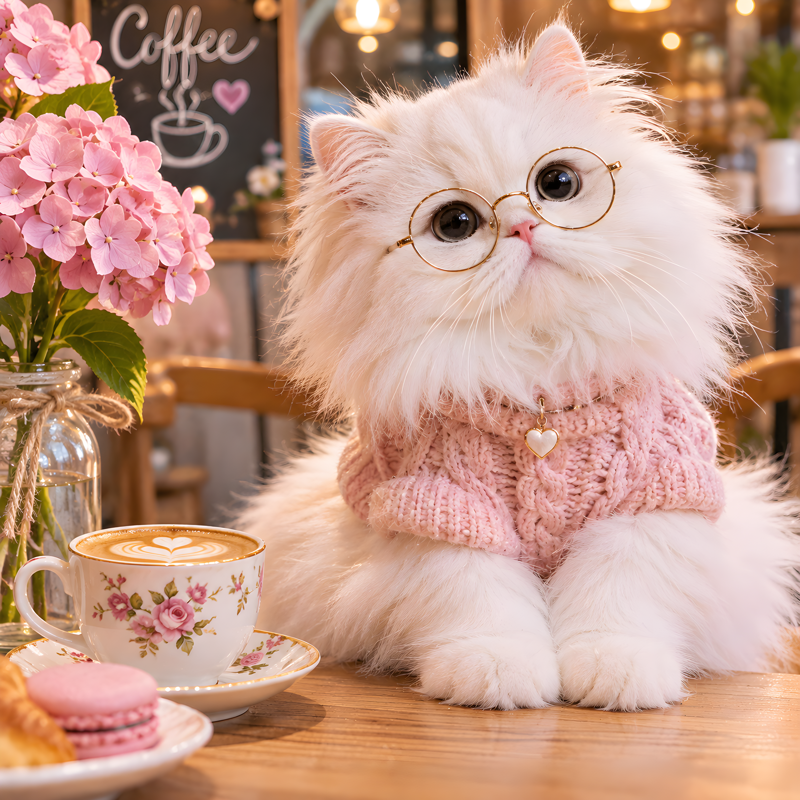

/content/drive/MyDrive/Real-ESRGAN-Colab/outputs/20261118_001942/persian_cat_glasses_coffee_ESRGAN_RealESRGAN_x4plus.png
ZIP: /content/drive/MyDrive/Real-ESRGAN-Colab/outputs/20261118_001942/restored_images.zip


In [12]:
# @title 7. Preview outputs { display-mode: "form" }
preview_size = 800 # @param [400,600,800,1200] {type:"raw"}
from IPython.display import display
from PIL import Image
for p in out_paths:
    with Image.open(p) as img:
        preview=img.copy()
        preview.thumbnail((int(preview_size),int(preview_size)))
        display(preview)
    print(p)
print("ZIP:",zip_path)

### Versions, troubleshooting & paid GPU notes
- **Python:** The notebook checks Python 3.10–3.13 and uses the **Colab interpreter**, rather than secretly switching Python versions inside an active kernel. If Colab provides a newer unsupported Python, use a compatible runtime or update the notebook after testing.
- **PyTorch/CUDA:** Use the working Colab-provided CUDA PyTorch/torchvision pair. A `uv`-installed *CPU-only* Torch wheel would break L4 acceleration, so this notebook intentionally avoids replacing it.
- **Installation repeat:** Drive preserves repo, weights and uv cache. A new session must restore packages, and Colab may require Drive authentication again. The *installed site-packages cannot simply be reused* after Colab rebuilds the runtime.
- **Version compatibility:** BasicSR 1.4.2 still references a removed torchvision import. The notebook patches that one import in the current runtime. This may need changes if upstream libraries evolve.
- **Fastest usage:** Upload locally, run on GPU, write outputs to Drive; avoid running the neural model directly on slow Drive files.
- **L4 selection:** Choosing L4 is a Colab runtime UI action; neither notebook code nor Colab Pro guarantees availability. **High-RAM** refers to CPU/system RAM, not GPU VRAM.
- **QR correctness:** Use Real-ESRGAN on a logo/photo **before** generating the QR. Never trust an AI-processed QR pattern without rescanning.
- **Pro charges:** Execute only the cells you need; don't keep an idle GPU runtime connected. Colab compute-unit rates and allocations change.

Repository: https://github.com/orioninsist/Real-ESRGAN